# Python · Kriging vs scikit-learn, SMT, OpenTURNS, GPy

**Idea.** How does libKriging compare with the Python GP packages, first as an
implementation (same hyperparameters → same numbers), then as a tool (default fits:
accuracy, calibration, cost) on 10 functions?

**Reference.** Scikit-learn, SMT, OpenTURNS and GPy.

**Tags.** class: Kriging · kernel: gauss, matern5_2 ·
compared to: scikit-learn, SMT, OpenTURNS, GPy

Two kinds of comparisons, which should not be confused:

1. **Same model, same hyperparameters → same numbers.** With θ, σ², β fixed,
   libKriging's predictor and likelihood are textbook formulas: another
   implementation must give the same values to rounding error. Done against
   scikit-learn (`RBF` = libKriging's `gauss`, both product-form) and
   OpenTURNS (product of 1D Matérn 5/2 = libKriging's `matern5_2`). A gap
   here is a bug in one of the packages (error-level).
2. **Same problem, each package's default fit → accuracy and cost.** Each
   package estimates its hyperparameters its own way (optimizer, restarts,
   bounds, mean model), so differences are expected; the table is a
   benchmark, and the checks are warn-level: libKriging should not be
   markedly less accurate than the best package.

Packages (each installed below, and skipped if that fails): scikit-learn,
SMT, OpenTURNS, GPy.

In [1]:
# Setup for running this notebook outside the repository (Colab, Binder, a lone copy):
# nothing to do in the repository itself (CI, local runs). Otherwise the repository
# (datasets of data/, helpers of tools/python/gallery.py) is cloned and the released pylibkriging installed.
import importlib
import os
import subprocess
import sys
from pathlib import Path

if not Path("tools/known_issues.csv").is_file():
    if not Path("gallery/tools/known_issues.csv").is_file():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/libKriging/gallery"], check=True)
    os.chdir("gallery")
    try:
        import pylibkriging  # noqa: F401
    except ImportError:
        r = subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "pylibkriging"],
                           capture_output=True, text=True)
        if r.returncode != 0:
            raise RuntimeError(
                f"pylibkriging could not be installed for Python {sys.version_info.major}.{sys.version_info.minor} "
                "(PyPI has wheels for CPython 3.10 to 3.12 only). On Colab: Runtime > Change runtime version > "
                "2026.07 (Python 3.12), then run again.\n" + r.stderr[-500:])
        importlib.invalidate_caches()
sys.path.insert(0, str(Path("tools/python").resolve()))  # for "import gallery" (tools/python/gallery.py)
print("working directory:", os.getcwd())

working directory: /home/runner/work/gallery/gallery


## Installing scikit-learn, SMT, OpenTURNS, GPy

With pip, into the kernel's environment, numpy pinned to its installed version
(a package that would downgrade it is not installed: the libKriging extension
is built against it). A package that cannot be installed is skipped, and
reported.

In [2]:
import importlib
import subprocess
import sys

import numpy

for package in ["scikit-learn", "smt", "openturns", "GPy"]:
    r = subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", package, f"numpy=={numpy.__version__}"],
                       capture_output=True, text=True)
    print(f"{package}: " + ("installed" if r.returncode == 0 else "NOT installed\n" + r.stderr.strip()[-800:]))
importlib.invalidate_caches()

scikit-learn: installed


smt: installed


openturns: installed


GPy: installed


In [3]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pylibkriging as lk

import gallery
from gallery import TESTS, design, metrics, compat

warnings.filterwarnings("ignore")
suite = gallery.Suite("vs-sklearn-SMT-OpenTURNS-GPy_Kriging_python")
sk = compat.optional("sklearn.gaussian_process")
smt = compat.optional("smt.surrogate_models")
ot = compat.optional("openturns")
GPy = compat.optional("GPy")
print("pylibkriging", compat.version(), "| sklearn", bool(sk), "| SMT", bool(smt), "| OpenTURNS", bool(ot),
      "| GPy", bool(GPy))


def lk_fixed(y, X, kernel, theta, sigma2, beta):
    return lk.Kriging(y, X, kernel, optim="none",
                      parameters={"theta": np.reshape(theta, (1, -1)), "is_theta_estim": False,
                                  "sigma2": float(sigma2), "is_sigma2_estim": False,
                                  "beta": np.reshape(beta, (-1, 1)), "is_beta_estim": False})

pylibkriging 1.2.2 | sklearn True | SMT True | OpenTURNS True | GPy True


## 1. Same hyperparameters, same numbers

In [4]:
tf = TESTS["hartmann3"]
X, y, Xt, yt = design.dataset(tf, 40, n_test=300, seed=81)
kg = lk.Kriging(y, X, "gauss")
theta, sigma2, beta = np.ravel(kg.theta()), float(kg.sigma2()), float(np.ravel(kg.beta())[0])
k_simple = lk_fixed(y, X, "gauss", theta, sigma2, beta)  # simple kriging, known beta
m_lk, s_lk, *_ = (np.ravel(a) for a in k_simple.predict(Xt, return_stdev=True)[:2])

if sk is not None:
    from sklearn.gaussian_process import GaussianProcessRegressor
    from sklearn.gaussian_process.kernels import RBF, ConstantKernel

    kern = ConstantKernel(sigma2, "fixed") * RBF(theta, "fixed")
    gp = GaussianProcessRegressor(kern, alpha=1e-12, optimizer=None, normalize_y=False).fit(X, y - beta)
    m_sk, s_sk = gp.predict(Xt, return_std=True)
    suite.check_close("sklearn RBF == libKriging gauss: simple kriging mean", m_sk + beta, m_lk, rtol=1e-6,
                atol=1e-7 * np.std(y))
    suite.check_close("sklearn RBF == libKriging gauss: simple kriging stdev (beta fixed)", s_sk, s_lk, rtol=1e-4,
                atol=1e-6 * np.sqrt(sigma2))
    # with beta estimated, libKriging's stdev is the universal kriging one: the simple kriging variance
    # plus the trend-estimation term (f - F'C^-1 c)^2 / (F'C^-1 F), computed here by hand
    C = kern(X); c = kern(X, Xt)
    w = np.linalg.solve(C, c)
    one = np.ones((len(y), 1))
    v_uk = s_sk ** 2 + ((1 - one.T @ w) ** 2).ravel() / (one.T @ np.linalg.solve(C, one)).item()
    s_uk = np.ravel(kg.predict(Xt, return_stdev=True)[1])
    suite.check_close("libKriging gauss (beta estimated) stdev == universal kriging formula", s_uk, np.sqrt(v_uk),
                rtol=1e-4, atol=1e-6 * np.sqrt(sigma2))
    # the (concentrated) log-likelihood at the MLE equals the full Gaussian log-density at (theta, sigma2, beta)
    lml = gp.log_marginal_likelihood_value_
    suite.check_close("sklearn log-marginal-likelihood == libKriging logLikelihood()", lml, kg.logLikelihood(),
                rtol=1e-6)
else:
    suite.check_skip("sklearn exact comparison", "scikit-learn not installed")

[KNOWN] sklearn RBF == libKriging gauss: simple kriging stdev (beta fixed): value=0.0333918 expected rtol 0.0001, atol 1.09021e-06 With beta fixed (is_beta_estim=False) predict still adds the trend-estimation variance (universal kriging) instead of the simple kriging variance


In [5]:
if ot is not None:
    km = lk.Kriging(y, X, "matern5_2")
    th, s2 = np.ravel(km.theta()), float(km.sigma2())
    cov = ot.ProductCovarianceModel([ot.MaternModel([t], [1.0], 2.5) for t in th])
    cov.setAmplitude([np.sqrt(s2)])
    basis = ot.ConstantBasisFactory(3).build()
    algo = ot.KrigingAlgorithm(ot.Sample(X), ot.Sample(y.reshape(-1, 1)), cov, basis)
    algo.setOptimizeParameters(False)
    ot.ResourceMap.SetAsScalar("GeneralLinearModelAlgorithm-DefaultOptimizationLowerBound", 1e-6)
    algo.run()
    res = algo.getResult()
    m_ot = np.ravel(res.getConditionalMean(ot.Sample(Xt)))
    v_ot = np.ravel(res.getConditionalMarginalVariance(ot.Sample(Xt)))
    # OpenTURNS re-estimates beta by GLS: compare with libKriging's universal kriging at the same theta, sigma2
    ku = lk.Kriging(y, X, "matern5_2", optim="none",
                    parameters={"theta": th.reshape(1, -1), "is_theta_estim": False,
                                "sigma2": s2, "is_sigma2_estim": False})
    m_u, s_u = (np.ravel(a) for a in ku.predict(Xt, return_stdev=True)[:2])
    suite.check_close("OpenTURNS product Matern 5/2 == libKriging matern5_2: mean", m_ot, m_u, rtol=1e-6,
                atol=1e-6 * np.std(y))
    suite.check_close("OpenTURNS product Matern 5/2 == libKriging matern5_2: variance (universal kriging)", v_ot, s_u ** 2,
                rtol=1e-4, atol=1e-8 * s2)
else:
    suite.check_skip("OpenTURNS exact comparison", "openturns not installed")

WRN - GeneralLinearModelAlgorithm is deprecated, use GaussianProcessFitter
WRN - KrigingAlgorithm is deprecated, use GaussianProcessRegression


## 2. Default fits on a set of test functions

Matérn 5/2 (or the closest the package offers), constant mean, maximum
likelihood with each package's default optimizer, 3 designs per case.

In [6]:
def fit_libkriging(X, y):
    k = lk.Kriging(y, X, "matern5_2")
    return lambda Z: tuple(np.ravel(a) for a in k.predict(Z, return_stdev=True)[:2])


def fit_libkriging_ms(X, y):
    k = lk.Kriging(y, X, "matern5_2", optim="BFGS10")
    return lambda Z: tuple(np.ravel(a) for a in k.predict(Z, return_stdev=True)[:2])


PACKAGES = {"pylibkriging": fit_libkriging, "pylibkriging BFGS10": fit_libkriging_ms}

if sk is not None:
    from sklearn.gaussian_process.kernels import Matern

    def fit_sklearn(X, y):
        d = X.shape[1]
        kern = ConstantKernel(1.0, (1e-3, 1e3)) * Matern(np.full(d, 0.5), (1e-3, 1e3), nu=2.5)
        gp = GaussianProcessRegressor(kern, alpha=1e-10, normalize_y=True, n_restarts_optimizer=5,
                                      random_state=0).fit(X, y)
        return lambda Z: gp.predict(Z, return_std=True)
    PACKAGES["scikit-learn"] = fit_sklearn

if smt is not None:
    def fit_smt(X, y):
        m = smt.KRG(corr="matern52", poly="constant", print_global=False)
        m.set_training_values(X, y)
        m.train()
        return lambda Z: (np.ravel(m.predict_values(Z)), np.sqrt(np.maximum(np.ravel(m.predict_variances(Z)), 0)))
    PACKAGES["SMT"] = fit_smt

if ot is not None:
    def fit_openturns(X, y):
        d = X.shape[1]
        cov = ot.MaternModel([0.5] * d, [float(np.std(y))], 2.5)
        algo = ot.KrigingAlgorithm(ot.Sample(X), ot.Sample(y.reshape(-1, 1)), cov, ot.ConstantBasisFactory(d).build())
        algo.run()
        r = algo.getResult()
        return lambda Z: (np.ravel(r.getConditionalMean(ot.Sample(Z))),
                          np.sqrt(np.maximum(np.ravel(r.getConditionalMarginalVariance(ot.Sample(Z))), 0)))
    PACKAGES["OpenTURNS"] = fit_openturns

if GPy is not None:
    def fit_gpy(X, y):
        kern = GPy.kern.Matern52(X.shape[1], ARD=True)
        m = GPy.models.GPRegression(X, y.reshape(-1, 1), kern, mean_function=None)
        m.Gaussian_noise.variance.fix(1e-8)
        m.optimize_restarts(3, verbose=False)
        def p(Z):
            mu, var = m.predict(Z)
            return np.ravel(mu), np.sqrt(np.maximum(np.ravel(var) - 1e-8, 0))
        return p
    PACKAGES["GPy"] = fit_gpy

CASES = {"branin": 30, "six_hump_camel": 40, "hartmann3": 50, "ishigami": 100, "friedman": 80,
         "otl_circuit": 80, "piston": 100, "borehole": 80, "wing_weight": 100, "hartmann6": 120}
rows = []
for fname, n in CASES.items():
    tf = TESTS[fname]
    for rep in range(3):
        X, y, Xt, yt = design.dataset(tf, n, n_test=1000, seed=100 + rep)
        for pkg, fit in PACKAGES.items():
            try:
                t0 = time.time()
                predictor = fit(X, y)
                t_fit = time.time() - t0
                t0 = time.time()
                m, s = predictor(Xt)
                t_pred = time.time() - t0
                rows.append(dict(function=fname, n=n, rep=rep, package=pkg, fit_s=t_fit, predict_s=t_pred,
                                 **metrics.all_metrics(yt, m, s)))
            except Exception as exc:  # noqa: BLE001
                rows.append(dict(function=fname, n=n, rep=rep, package=pkg, error=str(exc)[:100]))
                if pkg.startswith("pylibkriging"):
                    suite.check_true(f"{fname}/rep{rep}/{pkg}: fit", False, detail=str(exc)[:200])
res = pd.DataFrame(rows)
summary = res.groupby(["function", "package"], sort=False)[["q2", "nlpd", "coverage95", "fit_s"]].median()
for (fname, pkg), r in summary.iterrows():
    suite.metric(fname, pkg, **r.to_dict())
summary.unstack("package")["q2"].round(4)

WRN - GeneralLinearModelAlgorithm is deprecated, use GaussianProcessFitter
WRN - KrigingAlgorithm is deprecated, use GaussianProcessRegression


WRN - GeneralLinearModelAlgorithm is deprecated, use GaussianProcessFitter
WRN - KrigingAlgorithm is deprecated, use GaussianProcessRegression


WRN - GeneralLinearModelAlgorithm is deprecated, use GaussianProcessFitter
WRN - KrigingAlgorithm is deprecated, use GaussianProcessRegression


WRN - GeneralLinearModelAlgorithm is deprecated, use GaussianProcessFitter
WRN - KrigingAlgorithm is deprecated, use GaussianProcessRegression


WRN - GeneralLinearModelAlgorithm is deprecated, use GaussianProcessFitter
WRN - KrigingAlgorithm is deprecated, use GaussianProcessRegression


...

WRN - GeneralLinearModelAlgorithm is deprecated, use GaussianProcessFitter
WRN - KrigingAlgorithm is deprecated, use GaussianProcessRegression


WRN - GeneralLinearModelAlgorithm is deprecated, use GaussianProcessFitter
WRN - KrigingAlgorithm is deprecated, use GaussianProcessRegression


WRN - GeneralLinearModelAlgorithm is deprecated, use GaussianProcessFitter
WRN - KrigingAlgorithm is deprecated, use GaussianProcessRegression


WRN - GeneralLinearModelAlgorithm is deprecated, use GaussianProcessFitter
WRN - KrigingAlgorithm is deprecated, use GaussianProcessRegression


package,pylibkriging,pylibkriging BFGS10,scikit-learn,SMT,OpenTURNS,GPy
function,,,,,,
branin,0.9999,0.9999,0.9996,0.9999,0.9982,0.9998
six_hump_camel,0.9994,0.9994,0.0163,0.9996,0.9567,0.9360
hartmann3,0.9861,0.9861,0.9839,0.9859,0.9847,0.9850
ishigami,0.2596,0.9357,0.8311,0.4992,0.8873,0.8873
friedman,0.9998,0.9998,0.9998,0.9999,0.9909,1.0000
otl_circuit,0.9999,0.9999,0.9999,1.0000,0.9978,0.9999
piston,0.9975,0.9975,0.9987,0.9975,0.9906,0.9987
borehole,0.9997,0.9997,0.9999,0.9999,0.9962,0.9999
wing_weight,0.9997,0.9997,0.9980,0.9999,0.9931,0.9980


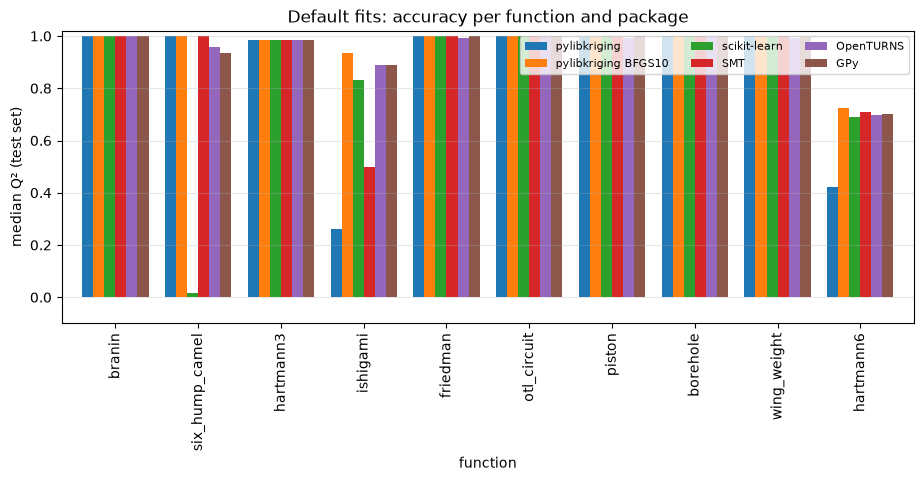

In [7]:
q2tab = summary.unstack("package")["q2"].clip(lower=-0.1)
q2tab.plot.bar(figsize=(11, 3.8), width=.8)
plt.ylabel("median Q² (test set)"); plt.ylim(-0.1, 1.02); plt.legend(ncol=3, fontsize=8); plt.grid(axis="y", alpha=.3)
plt.title("Default fits: accuracy per function and package"); plt.show()

In [8]:
summary.unstack("package")[["fit_s"]].round(3)

fit_s                                                    \
package        pylibkriging pylibkriging BFGS10 scikit-learn    SMT OpenTURNS   
function                                                                        
branin                0.001               0.006        0.034  0.194     0.002   
six_hump_camel        0.001               0.015        0.036  0.246     0.003   
hartmann3             0.006               0.039        0.043  0.249     0.007   
ishigami              0.009               0.103        0.111  0.670     0.019   
friedman              0.005               0.065        0.062  1.113     0.013   
otl_circuit           0.004               0.043        0.120  1.608     0.024   
piston                0.010               0.109        0.206  3.037     0.047   
borehole              0.005               0.057        0.234  2.916     0.037   
wing_weight           0.009               0.103        0.170  6.699     0.081   
hartmann6             0.019               0.293        0.309  2.717     0.058   

                       
package           GPy  
function               
branin          0.090  
six_hump_camel  0.066  
hartmann3       0.031  
ishigami        0.066  
friedman        0.238  
otl_circuit     0.109  
piston          0.153  
borehole        0.117  
wing_weight     0.177  
hartmann6       0.065

In [9]:
for fname in CASES:
    s = summary.loc[fname]["q2"]
    others = s.drop(index=[p for p in s.index if p.startswith("pylibkriging")])
    if len(others):
        suite.check_greater(f"{fname}: Q2(pylibkriging) - best other package", s["pylibkriging"] - others.max(), -0.02,
                      severity="warn", detail=f"best: {others.idxmax()}")
    suite.check_greater(f"{fname}: Q2(pylibkriging BFGS10) - best other package", s["pylibkriging BFGS10"] - others.max(),
                  -0.05, detail=f"best: {others.idxmax()}") if len(others) else None
    suite.check_greater(f"{fname}: Q2(pylibkriging BFGS10) > 0.5", s["pylibkriging BFGS10"], 0.5)

[WARN] ishigami: Q2(pylibkriging) - best other package: value=-0.627696 expected > -0.02 best: GPy
[WARN] hartmann6: Q2(pylibkriging) - best other package: value=-0.285531 expected > -0.02 best: SMT


## Summary

The metrics of this notebook, the number of checks per status, and every check that
did not pass (FAIL: error-level, fails the run; WARN: warn-level; KNOWN: listed in
`tools/known_issues.csv`, with its issue; SKIP: feature absent from the installed version).
All of them are also written to `results/vs-sklearn-SMT-OpenTURNS-GPy_Kriging_python.checks.csv` and `.metrics.csv`.

In [10]:
suite.summary()

metric                                  q2    nlpd  coverage95   fit_s
case           package                                                
branin         pylibkriging         0.9999  0.1372       1.000  0.0007
               pylibkriging BFGS10  0.9999  0.1373       1.000  0.0058
               scikit-learn         0.9996  0.9285       1.000  0.0341
               SMT                  0.9999  0.1373       1.000  0.1935
               OpenTURNS            0.9982  1.5560       0.993  0.0020
               GPy                  0.9998  0.7216       1.000  0.0904
six_hump_camel pylibkriging         0.9994  0.0430       0.956  0.0012
               pylibkriging BFGS10  0.9994  0.0429       0.956  0.0154
               scikit-learn         0.0163  4.6376       0.915  0.0361
               SMT                  0.9996 -0.1237       0.962  0.2455
               OpenTURNS            0.9567  2.5545       0.872  0.0031
               GPy                  0.9360  2.4887       0.859  0.0663
hartmann3      pylibkriging         0.9861 -0.8472       0.956  0.0060
               pylibkriging BFGS10  0.9861 -0.8472       0.956  0.0393
               scikit-learn         0.9839 -0.7827       0.951  0.0433
               SMT                  0.9859 -0.8419       0.956  0.2494
               OpenTURNS            0.9847 -0.8099       0.954  0.0065
               GPy                  0.9850 -0.8223       0.954  0.0310
ishigami       pylibkriging         0.2596  4.3899       0.849  0.0087
               pylibkriging BFGS10  0.9357  0.8574       0.905  0.1030
               scikit-learn         0.8311  1.5455       0.897  0.1108
               SMT                  0.4992  4.8736       0.789  0.6699
               OpenTURNS            0.8873  1.3935       0.901  0.0189
               GPy                  0.8873  1.3808       0.901  0.0665
friedman       pylibkriging         0.9998 -1.2973       0.998  0.0055
               pylibkriging BFGS10  0.9998 -1.2973       0.998  0.0651
               scikit-learn         0.9998 -1.3770       0.998  0.0619
               SMT                  0.9999 -1.8694       0.964  1.1131
               OpenTURNS            0.9909  0.4698       0.986  0.0130
               GPy                  1.0000 -2.2122       1.000  0.2377
otl_circuit    pylibkriging         0.9999 -3.4623       0.947  0.0042
               pylibkriging BFGS10  0.9999 -3.4623       0.947  0.0434
               scikit-learn         0.9999 -3.4306       0.922  0.1203
               SMT                  1.0000 -3.3337       0.791  1.6082
               OpenTURNS            0.9978 -1.6172       0.994  0.0238
               GPy                  0.9999 -3.4181       0.910  0.1086
piston         pylibkriging         0.9975 -3.8067       0.954  0.0103
               pylibkriging BFGS10  0.9975 -3.8067       0.954  0.1092
               scikit-learn         0.9987 -4.1050       0.960  0.2059
               SMT                  0.9975 -3.8666       0.909  3.0373
               OpenTURNS            0.9906 -2.9906       0.972  0.0470
               GPy                  0.9987 -4.1050       0.957  0.1532
borehole       pylibkriging         0.9997  1.0012       0.973  0.0049
               pylibkriging BFGS10  0.9997  1.0012       0.973  0.0566
               scikit-learn         0.9999  0.1945       0.969  0.2340
               SMT                  0.9999  0.2778       0.917  2.9157
               OpenTURNS            0.9962  2.5543       0.986  0.0374
               GPy                  0.9999  0.2996       0.936  0.1169
wing_weight    pylibkriging         0.9997  1.1152       0.962  0.0093
               pylibkriging BFGS10  0.9997  1.1151       0.962  0.1027
               scikit-learn         0.9980  2.5730       0.764  0.1704
               SMT                  0.9999  0.6064       0.879  6.6992
               OpenTURNS            0.9931  2.8363       0.993  0.0814
               GPy                  0.9980  2.6276       0.757  0.1772
hartmann6      pylibkrig

36 checks: PASS 33, FAIL 0, WARN 2, KNOWN 1, SKIP 0


,status,severity,check,value,expected,detail
0,KNOWN,error,sklearn RBF == libKriging gauss: simple krigin...,0.0333918,"rtol 0.0001, atol 1.09021e-06",With beta fixed (is_beta_estim=False) predict ...
1,WARN,warn,ishigami: Q2(pylibkriging) - best other package,-0.627696,> -0.02,best: GPy
2,WARN,warn,hartmann6: Q2(pylibkriging) - best other package,-0.285531,> -0.02,best: SMT


In [11]:
suite.finalize()

vs-sklearn-SMT-OpenTURNS-GPy_Kriging_python: PASS 33, FAIL 0, WARN 2, KNOWN 1, SKIP 0


{'PASS': 33, 'FAIL': 0, 'WARN': 2, 'KNOWN': 1, 'SKIP': 0}